# Introducción a OpenCV

OpenCV es una biblioteca de visión por computadora de código abierto. Permite desarrollar rápidamente aplicaciones complejas de Visión por Computador y Aprendizaje Automático, ofreciendo un amplio conjunto de funciones.
Originalmente desarrollado en C/C++, ahora OpenCV tiene controladores también para Java y Python y puede explotarse también en aplicaciones de iOS y Android.
En Python, OpenCV y NumPy están estrictamente relacionados

En particular, algunas de las funciones que ofrece OpenCV son:

- Manejo de imágenes (leer una imagen, escribir una imagen, etc.)
- Detección de esquinas (Harris,Shi-Tomasi, etc.)
- Calibración de la cámara
- Detección y descripción de funciones (ORB, SIFT, SURF, etc.)
- Estimación de profundidad (coincidencia de bloques, SGM, etc.)
- Flujo óptico (Lucas-Kanade)
- y muchos más

**Instalación**

Podemos instalar OpenCV directamente mediante pip, llamando

```
pip install opencv-python
```

Luego, en nuestro script Python, podemos importarlo de la siguiente manera:

In [1]:
import cv2 as cv
import matplotlib.pyplot as plt

Como decíamos, OpenCV ofrece funciones para leer y escribir imágenes.
Podemos abrir una imagen usando la función **imread**:

```
img = cv.imread('ruta_de_imagen.formato')
```

Además, es capaz de manejar varios formatos de imagen (png, jpeg, etc.) y datos.
tipos (8 bits, 16 bits, etc.)

In [2]:
img = cv.imread('img/img.jpg')

Para mostrar una imagen se utiliza el siguiente método:

```
cv.imshow('Nombre', img)
```

`cv.imshow` abre una ventana nativa del sistema operativo — funciona en un script corrido desde la terminal, pero no dentro de una notebook. En Jupyter (y en Colab) mostramos las imágenes con `matplotlib` en su lugar.

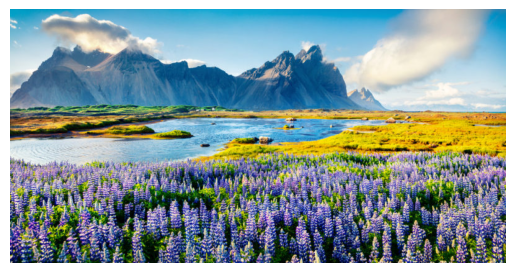

In [3]:
# cv2_imshow es específico de Colab; en Jupyter mostramos con matplotlib
# (y convertimos de BGR, que es como OpenCV lee las imágenes, a RGB)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Configuraciones a tener en cuenta:

```
cv.waitKey(0)
```

- Función: cv.waitKey() es una función que espera a que se presione una tecla.
- Argumento: El argumento 0 indica que la función esperará indefinidamente hasta que se presione cualquier tecla.
- Uso Común: Esta función es útil para pausar la ejecución del programa y permitir al usuario ver la imagen mostrada en una ventana antes de cerrarla.
- Funcionamiento: Mientras cv.waitKey(0) está en ejecución, el programa se encuentra en un estado de espera. En cuanto se presiona cualquier tecla, la función devuelve el valor ASCII de la tecla presionada y el programa continúa.

```
cv.destroyAllWindows()
```

- Función: cv.destroyAllWindows() es una función que cierra todas las ventanas abiertas creadas por OpenCV.
- Uso Común: Después de mostrar una imagen usando cv.imshow(), y esperar a que el usuario presione una tecla con cv.waitKey(), cv.destroyAllWindows() se usa para cerrar todas las ventanas de manera ordenada.
- Importancia: Esto es importante para liberar los recursos del sistema asociados con las ventanas de OpenCV y evitar problemas con la gestión de ventanas si se ejecutan múltiples scripts o iteraciones en un mismo programa.

## Una imagen es una matriz

Antes de usar OpenCV, vale la pena construir una imagen "a mano" con NumPy para que quede claro qué es, en el fondo, una imagen digital: una matriz de números.

### Escala de grises

En una imagen en escala de grises, cada píxel es un único número entre 0 (negro) y 255 (blanco).

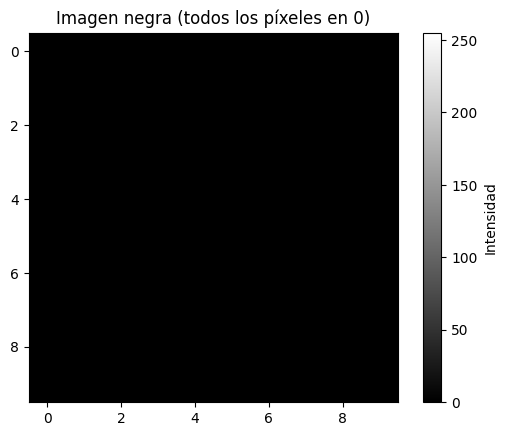

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Una imagen de 10x10 píxeles, todos en negro (0)
img_gris = np.zeros((10, 10), dtype=np.uint8)

plt.imshow(img_gris, cmap='gray', vmin=0, vmax=255)
plt.title('Imagen negra (todos los píxeles en 0)')
plt.colorbar(label='Intensidad')
plt.show()

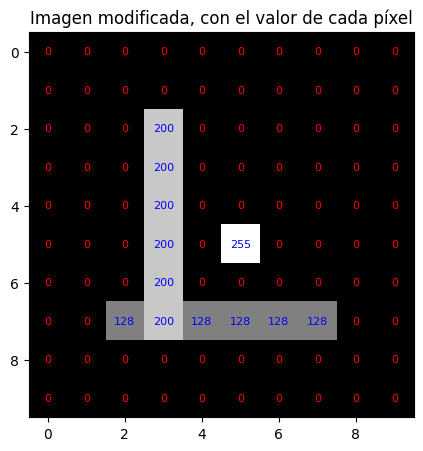

In [5]:
# Modificamos algunos píxeles para formar un patrón
img_gris[5, 5] = 255            # un píxel blanco en el centro
img_gris[7, 2:8] = 128          # una línea gris medio
img_gris[2:8, 3] = 200          # una línea gris claro

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img_gris, cmap='gray', vmin=0, vmax=255)
ax.set_title('Imagen modificada, con el valor de cada píxel')

# Superponemos el valor numérico de cada píxel
for i in range(10):
    for j in range(10):
        color = 'red' if img_gris[i, j] < 128 else 'blue'
        ax.text(j, i, str(img_gris[i, j]), ha='center', va='center', color=color, fontsize=8)
plt.show()

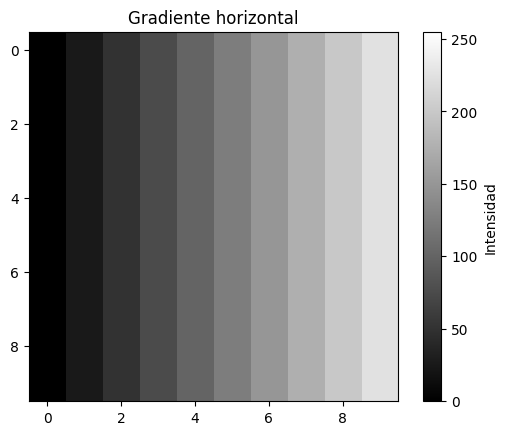

In [6]:
# Un gradiente horizontal: la intensidad crece de izquierda a derecha
img_gradiente = np.zeros((10, 10), dtype=np.uint8)
for col in range(10):
    img_gradiente[:, col] = col * 25

plt.imshow(img_gradiente, cmap='gray', vmin=0, vmax=255)
plt.title('Gradiente horizontal')
plt.colorbar(label='Intensidad')
plt.show()

### Color

Una imagen a color es lo mismo, pero con un tercer eje: en vez de un número por píxel, tenemos tres (uno por canal — rojo, verde y azul).

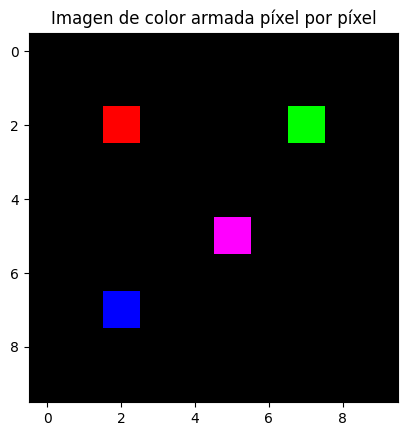

In [7]:
# 10x10 píxeles, 3 canales (R, G, B)
img_color = np.zeros((10, 10, 3), dtype=np.uint8)

# Pintamos algunos píxeles a mano
img_color[2, 2] = [255, 0, 0]      # rojo
img_color[2, 7] = [0, 255, 0]      # verde
img_color[7, 2] = [0, 0, 255]      # azul
img_color[5, 5] = [255, 0, 255]    # magenta

plt.imshow(img_color)
plt.title('Imagen de color armada píxel por píxel')
plt.show()

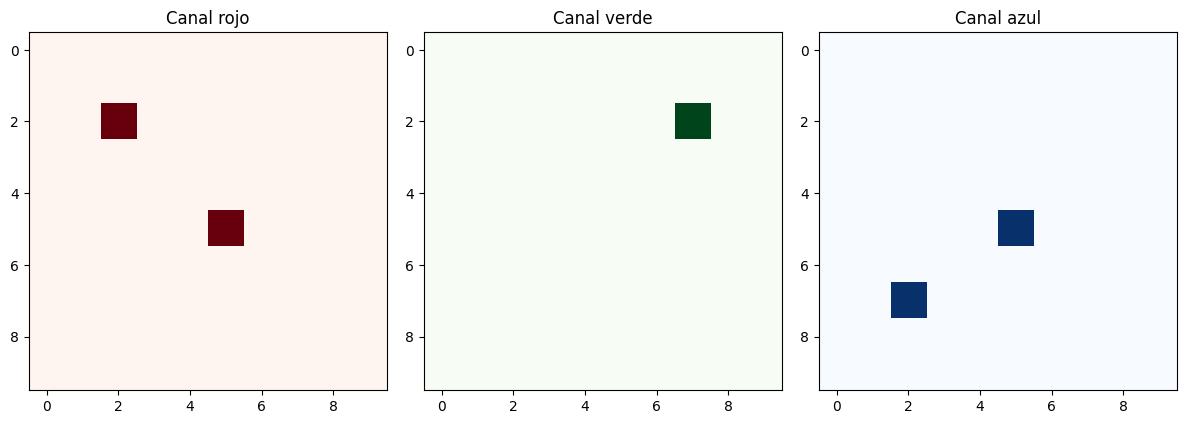

In [8]:
# Separamos los canales: img_color[:, :, k] es el canal k (0=R, 1=G, 2=B)
canal_r = img_color[:, :, 0]
canal_g = img_color[:, :, 1]
canal_b = img_color[:, :, 2]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(canal_r, cmap='Reds'); axes[0].set_title('Canal rojo')
axes[1].imshow(canal_g, cmap='Greens'); axes[1].set_title('Canal verde')
axes[2].imshow(canal_b, cmap='Blues'); axes[2].set_title('Canal azul')
plt.tight_layout()
plt.show()

Esta misma idea — una imagen como arreglo de NumPy, con o sin un eje extra para los canales de color — es exactamente cómo OpenCV representa las imágenes. Veamos ahora cómo cargar y manipular imágenes reales con OpenCV.

## Primeros pasos en OpenCV

- Imágenes en OpenCV
- Cargar, salvar y mostrar imágenes
- Acceder a los datos de los píxeles
- Manipular los canales de color
- Uso de matplotlib

In [9]:
#Si queremos que las imágenes sean mostradas en una ventana emergente quitar el inline
# se muestra imagen debajo que cada celda
%matplotlib inline

# se muestra imagen en ventana emergente
#%matplotlib qt

# OpenCV-Python utiliza NumPy para el manejo de imágenes
import numpy as np
# cv2 es el módulo python para acceder a OpenCV
import cv2 as cv
# Usamos las poderosas herramientas de graficación de matplotlib para mostrar imágenes, perfiles, histogramas, etc
import matplotlib.pyplot as plt

In [10]:
# Cargar una imagen en modo monocromático (un canal)
img = cv.imread('img/imgBloque1.jpg', cv.IMREAD_GRAYSCALE)

# Dimensión de la imagen
print(f'Tamaño imagen: {img.shape} pix')
print(img)

Tamaño imagen: (480, 640) pix
[[ 62  62  61 ... 255 223 177]
 [ 62  61  61 ... 255 222 176]
 [ 61  61  61 ... 255 220 173]
 ...
 [ 67  68  69 ...  98  99 101]
 [ 66  67  68 ... 104 104 103]
 [ 65  65  67 ... 108 107 105]]


**cv.IMREAD_GRAYSCALE**

Es una constante utilizada en OpenCV para especificar que una imagen debe ser cargada en modo de escala de grises. Esta constante se utiliza como un argumento en la función cv.imread() para cargar una imagen en escala de grises.

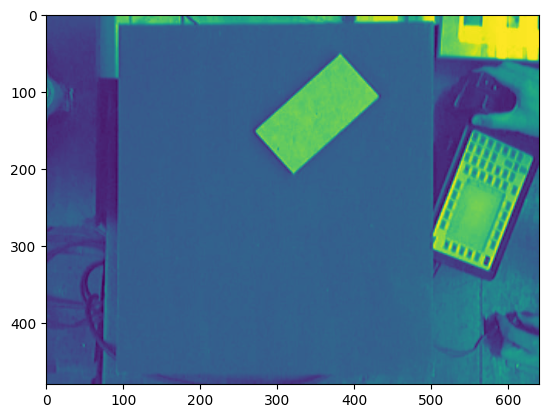

In [11]:
# Muestro la imagen con matplotlib
plt.figure()
plt.imshow(img)
plt.show()

**¿Por que se ve asi?**

Porque estamos 'intentando' mostrar la imagen a color a partir de la imagen en gris.

**plt.figure():**

Este comando crea una nueva figura de Matplotlib. Si no hay ninguna figura actual, esta función la creará. Si ya hay una figura, esta función generará una nueva figura independiente.

**plt.imshow(img, cmap='gray'):**

Este comando muestra la imagen img en la figura creada anteriormente. **cmap='gray'** especifica que la imagen se mostrará en escala de grises. La función imshow() toma la matriz de la imagen img y la interpreta como una imagen. La opción cmap='gray' especifica el mapa de colores que se utilizará para mostrar la imagen, en este caso, se mostrará en escala de grises.

**plt.show():**

Este comando muestra la figura creada anteriormente. Es importante mencionar que Matplotlib utiliza la ventana de visualización predeterminada de su entorno para mostrar la figura.

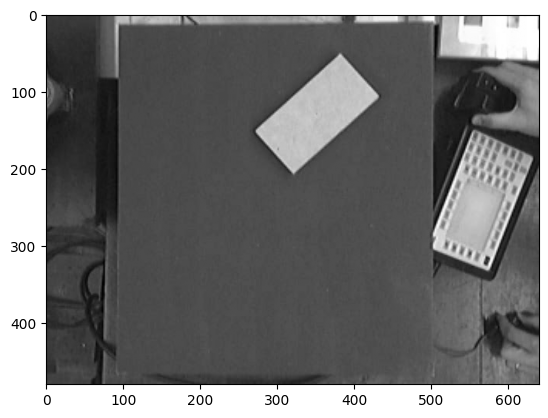

In [12]:
# Quiero ver la imagen en tonos de grises
plt.imshow(img, cmap='gray')
plt.show()

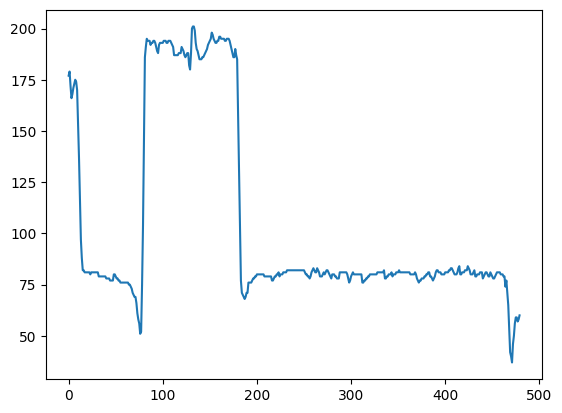

In [13]:
# Para ver un perfil. Es decir la intensidad a lo largo de la columna 350 por ejemplo
perfil = img[:,350];
plt.plot(perfil)
plt.show()

Ahora realizaremos una marca en la imagen para indicar la línea que usamos para tomar el perfil

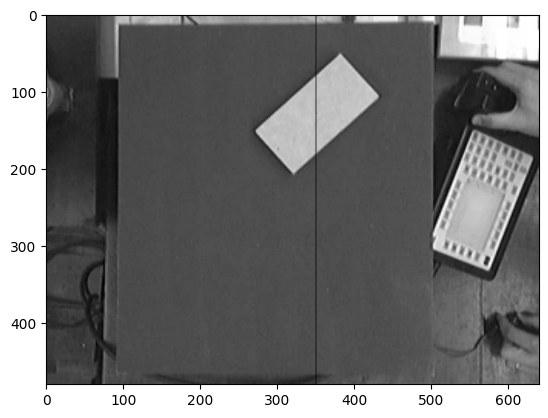

In [14]:
img_anotada = img.copy() # Copia de imagen original
img_anotada[:, 350] = 0  # Ponemos en '0' la columna 350
plt.figure()
plt.imshow(img_anotada,cmap='gray')
plt.show()

- Copia de la imagen original: **img.copy()** crea una copia de la imagen original img en una nueva variable llamada img_anotada. Esto garantiza que la manipulación que se realizará a continuación no afecte a la imagen original.

- Modificación de píxeles en una columna específica: **img_anotada[:, 350] = 0** establece el valor de los píxeles en la columna 350 de la imagen copiada (img_anotada) a cero. El uso de [:, 350] indica que estamos seleccionando todos los píxeles de todas las filas en la columna 350 y estableciendo su valor a cero. Esto efectivamente eliminará la información en la columna 350, creando una franja vertical negra en la imagen.

**Interpolación de pixeles**

La interpolación de píxeles vecinos es un proceso utilizado por Matplotlib (y otras bibliotecas de visualización de imágenes) para mostrar imágenes en una resolución mayor o menor que su resolución original. Cuando una imagen se visualiza en una ventana de tamaño diferente al de la imagen original, es necesario interpolar los valores de los píxeles de la imagen original para adaptarlos al nuevo tamaño de la ventana.

Por ejemplo, si se tiene una imagen de 100x100 píxeles y se visualiza en una ventana de 200x200 píxeles, Matplotlib necesitará interpolar los valores de los píxeles de la imagen original para generar una versión ampliada de la imagen que llene la ventana de 200x200 píxeles. La interpolación de píxeles vecinos implica calcular los valores de los píxeles adicionales en función de los valores de los píxeles vecinos en la imagen original.

Existen varios métodos de interpolación, como el método de interpolación más cercano (nearest), el método de interpolación bilineal (bilinear) y el método de interpolación bicúbica (bicubic). Estos métodos calculan los valores de los píxeles adicionales de diferentes maneras, pero todos se basan en los valores de los píxeles vecinos en la imagen original.

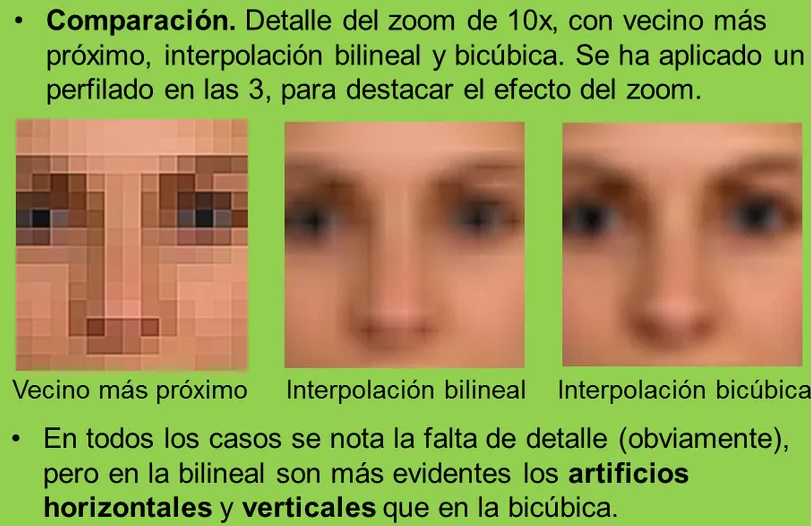

Mostrando con interpolacion nearest


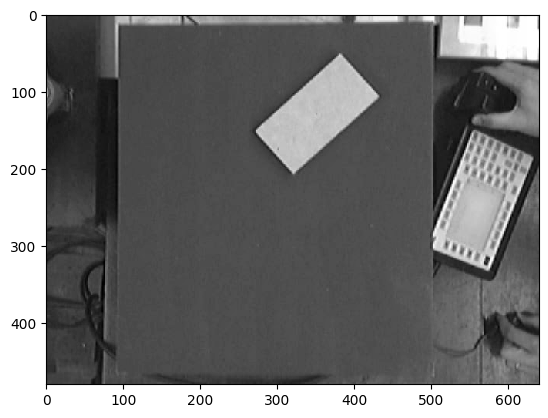

Mostrando con interpolacion bilinear


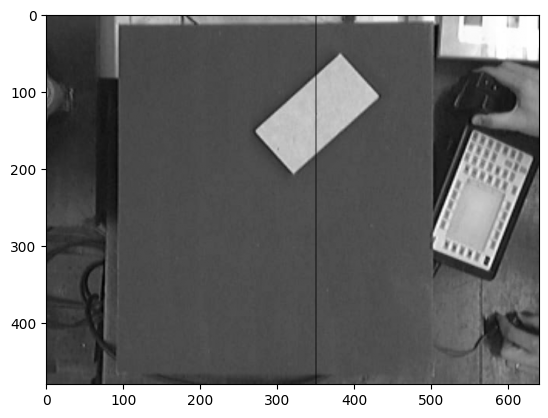

Mostrando con interpolacion bicubic


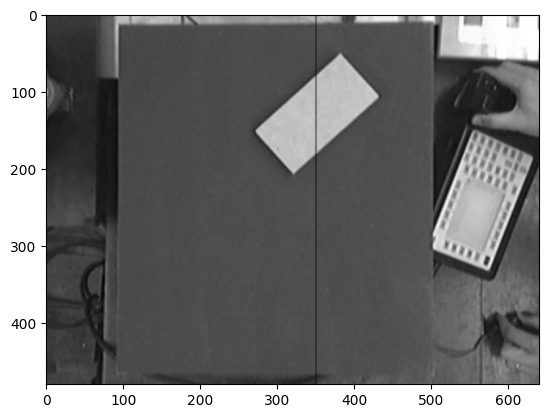

In [15]:
img_anotada = img.copy()
img_anotada[:,350]=0
for interp in ['nearest','bilinear','bicubic']:
    print('Mostrando con interpolacion {}'.format(interp))
    plt.figure()
    plt.imshow(img_anotada, cmap='gray', interpolation=interp)
    plt.show()

Tamaño imagen: (480, 640, 3)


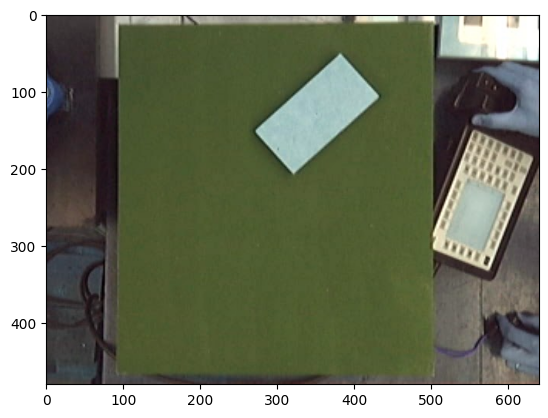

In [16]:
# Ahora quiero verla como imagen en color
img_color = cv.imread('img/imgBloque1.jpg')
# Dimensión de la imagen
print(f'Tamaño imagen: {img_color.shape}')
# Muestro la imagen color
plt.imshow(img_color)
plt.show()

**¿Que problema tenemos ahora?**

No tiene los colores originales.

La discrepancia en la apariencia de los colores entre la visualización con Matplotlib (plt.imshow()) y la visualización con OpenCV (cv.imshow()) puede deberse a diferencias en la interpretación del formato de color de la imagen por parte de estas bibliotecas.

Cuando se carga una imagen con OpenCV (cv.imread()), por defecto, la imagen se carga en el formato BGR (azul, verde, rojo). Sin embargo, Matplotlib espera que las imágenes estén en formato RGB (rojo, verde, azul) cuando las muestras con plt.imshow(). Esto significa que si se visualiza una imagen cargada con OpenCV directamente con Matplotlib, los canales de color se interpretarán de manera incorrecta, lo que puede resultar en una apariencia extraña o incorrecta de los colores.

- **OpenCV: Trabaja en formato BGR**

- **Matplotlib: Trabaja en formato RGB**

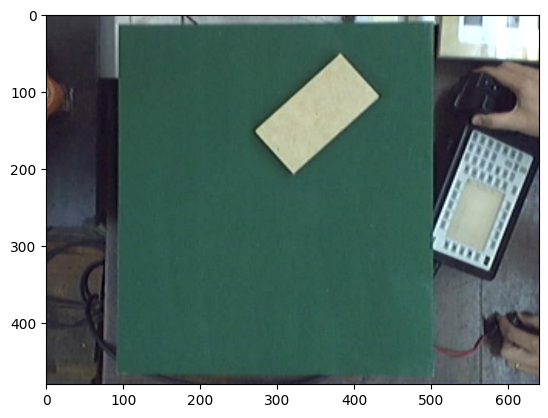

In [17]:
# Se pasa la imagen de BRG a RGB
imgRGB = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)
plt.imshow(imgRGB)
plt.show()

**cv.COLOR_BGR2RGB**

Es una constante utilizada en OpenCV para especificar la conversión de un espacio de color de BGR (azul, verde, rojo) a RGB (rojo, verde, azul). Se utiliza como argumento en la función cv.cvtColor() para realizar la conversión de color de una imagen de formato BGR a RGB.

### Ejercicio

Hallar una forma simple de invertir el orden de los canales (RGB) usando Numpy.

### Solución

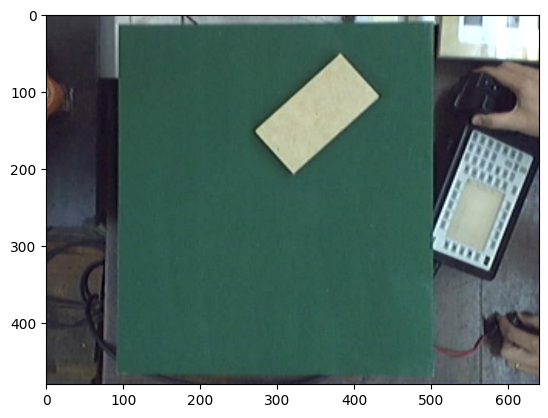

In [18]:
# Respuesta
imgRGB = img_color[:, :, ::-1]
plt.imshow(imgRGB)
plt.show()

# Otra
imgRGB = img_color[..., ::-1]

**img_color[:, :, ::-1]**

Selecciona todos los píxeles de la imagen img_color en todos los canales de color (rojo, verde, azul) pero invierte el orden de los canales. El orden original de los canales de color en OpenCV es BGR (azul, verde, rojo), pero al invertir el orden de los índices (::-1), se cambia el orden a RGB (rojo, verde, azul). Por lo tanto, esta operación convierte la imagen de formato BGR a formato RGB.

## Separación de Canales


Separar los canales de colores en imágenes puede ser conveniente en diversas situaciones:

- **Procesamiento por canal:** A veces, ciertos algoritmos o técnicas de procesamiento de imágenes pueden aplicarse de manera más efectiva o adecuada a un solo canal de color en lugar de a la imagen completa. Por ejemplo, en el procesamiento de imágenes médicas, puede ser útil trabajar con el canal de luminancia de una imagen en escala de grises para resaltar ciertas características.

- **Ajustes y correcciones específicas:** Al trabajar con colores, a menudo se necesitan ajustes específicos en un solo canal de color para corregir problemas como el balance de blancos, la saturación o la exposición. Separar los canales de color permite aplicar estos ajustes de manera selectiva a cada canal, lo que puede mejorar significativamente la calidad de la imagen.

- **Extracción de características:** En tareas de reconocimiento de patrones o detección de objetos, los canales de color individuales pueden contener información útil sobre ciertas características de la imagen. Separar los canales de color permite analizar y extraer estas características de manera más precisa.

- **Segmentación de objetos:** Algunos métodos de segmentación de imágenes se basan en características específicas de los canales de color para identificar y separar objetos de interés en una imagen. Separar los canales de color puede facilitar este proceso y mejorar los resultados de la segmentación.

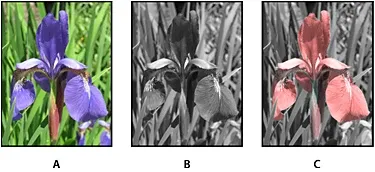

Si se quiere desempaquetar los canales de colores para trabajar por separado en cada canal se deberá realizar lo siguiente:

[[ 62  62  61 ... 254 222 176]
 [ 62  61  61 ... 254 221 175]
 [ 61  61  61 ... 254 219 172]
 ...
 [ 67  68  69 ...  88  91  93]
 [ 65  66  67 ...  94  96  95]
 [ 64  64  66 ...  98  99  97]]
Canal rojo


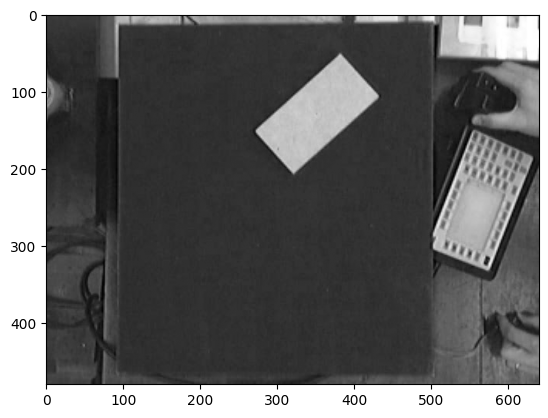

Canal verde


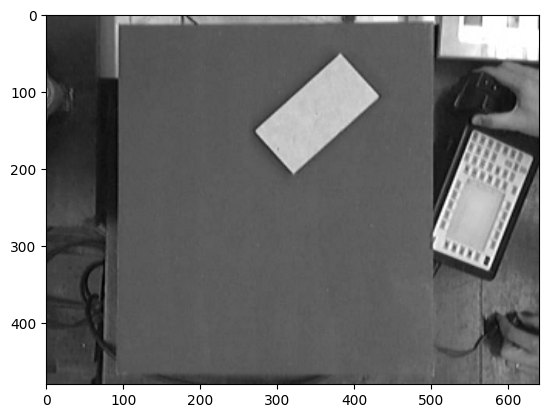

Canal azul


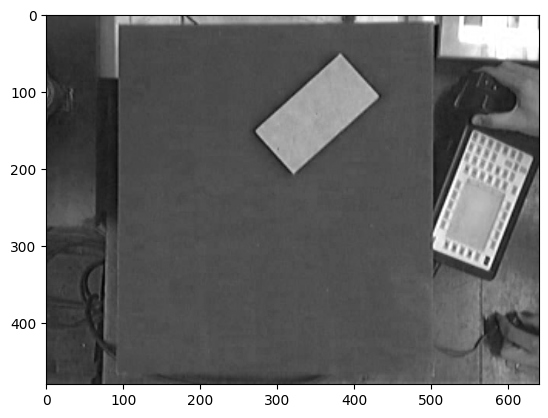

In [19]:
im_r, im_g, im_b = cv.split(imgRGB) # Desempaqueta imagen en R, G y B
print(im_r)
print('Canal rojo')
plt.imshow(im_r, cmap='gray')
plt.show()
print('Canal verde')
plt.imshow(im_g, cmap='gray')
plt.show()
print('Canal azul')
plt.imshow(im_b, cmap='gray')
plt.show()


**im_r, im_g, im_b = cv.split(imgRGB)**

Divide una imagen en sus tres canales de color individuales (rojo, verde y azul) y almacena cada canal por separado en tres variables distintas: im_r, im_g e im_b.

- cv.split(imgRGB): Esta función de OpenCV toma una imagen en formato RGB (imgRGB) y la divide en sus tres canales de color individuales: rojo, verde y azul. Devuelve estos canales de color como una lista de imágenes, donde cada imagen representa un canal de color.

- im_r, im_g, im_b = ...: Utilizando la asignación múltiple de Python, los tres canales de color se asignan a tres variables distintas: im_r para el canal rojo, im_g para el canal verde y im_b para el canal azul.

Después de ejecutar esta línea de código, se tendrá tres imágenes separadas (im_r, im_g e im_b), cada una de las cuales contiene solo un canal de color específico de la imagen original imgRGB. Estas imágenes individuales se pueden manipular o procesar por separado, por ejemplo, para realizar ajustes específicos en cada canal de color o para extraer características específicas de cada canal.

Ahora, se elimina los canales de color verde y azul de la imágen RGB y luego se reconstruye la imagen con solo el canal de color rojo.

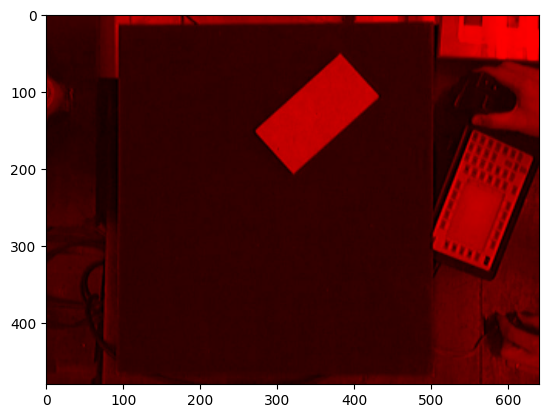

In [20]:
# Vamos a eliminar canal G y B. Y mezclamos para la reconstrucción
imgRGB2 = cv.merge((im_r, im_g * 0, im_b * 0))

plt.imshow(imgRGB2)
plt.show()

**Eliminación de los canales de color verde y azul:**

Se multiplican los píxeles de los canales de color verde (im_g) y azul (im_b) por cero. Esto significa que todos los valores de píxeles en los canales verde y azul se establecen en cero, lo que elimina efectivamente estos canales de color de la imagen. El canal de color rojo (im_r) no se modifica.

**Reconstrucción de la imagen con solo el canal de color rojo:**

Utilizando la función **cv.merge()**, se combinan los tres canales de color (rojo, verde y azul) en una sola imagen. Sin embargo, como los canales de color verde y azul se han eliminado previamente (multiplicados por cero), la imagen resultante (imgRGB2) contiene solo el canal de color rojo.

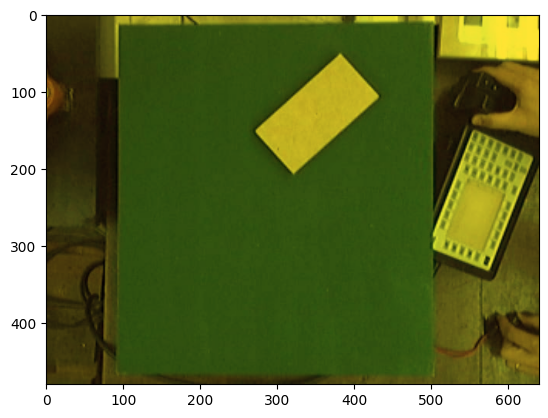

In [21]:
# Vamos a componer la imagen color con distintos pesos (intensidades) en los canales
# Notar el uso de uint8
imgRGB2 = cv.merge((im_r, np.uint8(im_g*0.9), np.uint8(im_b*0.2)))
plt.imshow(imgRGB2)
plt.show()

**Ajuste de pesos en los canales de color:**

Los valores de los píxeles en los canales de color verde (im_g) y azul (im_b) se multiplican por un factor de escala específico antes de ser combinados en la imagen final. En este caso, los valores de píxeles en el canal verde se multiplican por 0.9 y los valores de píxeles en el canal azul se multiplican por 0.2. Estos factores de escala ajustan los pesos relativos de los canales de color verde y azul en la imagen final.

En el contexto de imágenes, el tipo de datos **uint8** se utiliza comúnmente para representar los valores de intensidad de los píxeles, donde cada píxel puede tener un valor entre 0 y 255. Este tipo de datos es adecuado para imágenes en color, donde cada canal de color (rojo, verde, azul) se representa utilizando 8 bits, lo que permite un total de 256 niveles de intensidad para cada canal.

En el código, se utiliza np.uint8() para asegurarse de que los valores resultantes de los cálculos de los canales de color (im_g * 0.9 y im_b * 0.2) se ajusten al rango válido de valores uint8 (0 a 255) antes de combinarlos en la imagen final. Esto es importante para evitar posibles desbordamientos o errores de tipo cuando se realizan operaciones con valores de píxeles en imágenes.

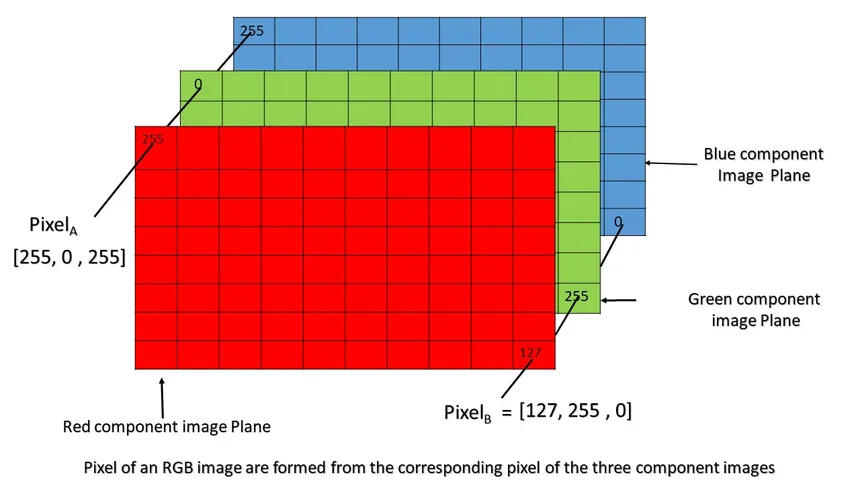

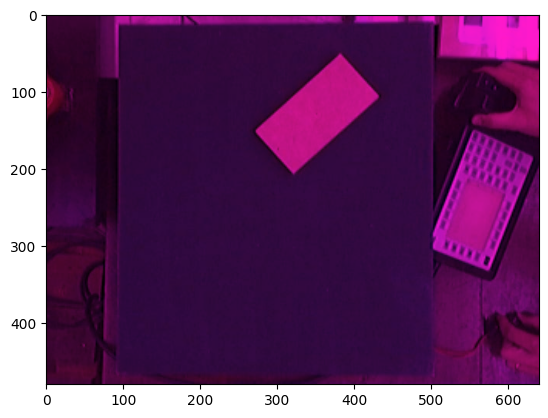

In [22]:
# Vamos a componer la imagen color con distintos pesos (intensidades) en los canales
# Notar el uso de uint8
imgRGB2 = cv.merge((im_r, np.uint8(im_g*0.1), np.uint8(im_b*0.8)))
plt.imshow(imgRGB2)
plt.show()

**Trazamiento de un perfil de intensidad de color sobre una columna específica de una imágen RGB**

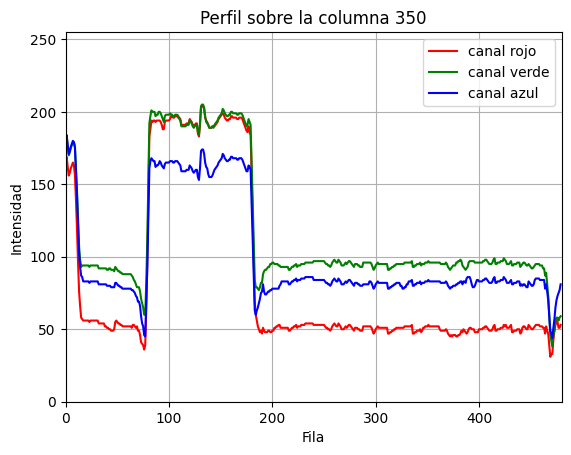

In [23]:
# Selecciona el índice de la columna sobre la cual se tomará el perfil de intensidad de color
idx_col = 350 # Seleccionamos columna 350 (rgb)

# Selecciona todos los píxeles de la columna especificada de la imagen RGB
perfil_color = imgRGB[:,idx_col]

# Se trazan tres líneas diferentes, una para cada componente de color (rojo, verde, azul)
plt.plot(perfil_color[:,0], color='r', label='canal rojo')
plt.plot(perfil_color[:,1], color='g', label='canal verde')
plt.plot(perfil_color[:,2], color='b', label='canal azul')

# Etiquetas y título del gráfico
plt.xlabel('Fila') # Etiqueta del eje x
plt.ylabel('Intensidad') # Etiqueta del eje y
plt.title(f'Perfil sobre la columna {idx_col}') # Título del gráfico

# Ajustes de visualización
plt.grid() # Agrega una cuadrícula al gráfico
plt.xlim(0, 480) # Límites del eje x
plt.ylim(0, 255) # Límites del eje

# Leyenda que muestra qué color representa cada componente de color en el gráfico
plt.legend()

# Mostrar el gráfico
plt.show()

**Selección de la columna de la imagen:**

```
perfil_color = imgRGB[:,idx_col]
```
Selecciona todos los píxeles de la columna especificada (idx_col) de la imagen RGB (imgRGB). Esto crea un perfil de intensidad de color a lo largo de esa columna, donde cada fila representa un píxel y las tres componentes de color (rojo, verde, azul) se almacenan en un arreglo tridimensional.



In [24]:
# Guardamos la imagen modificada
cv.imwrite('modificada.png', imgRGB2)

True

## Anotaciones en Imágenes

Funciones básicas para graficar líneas, círculos y texto

In [25]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

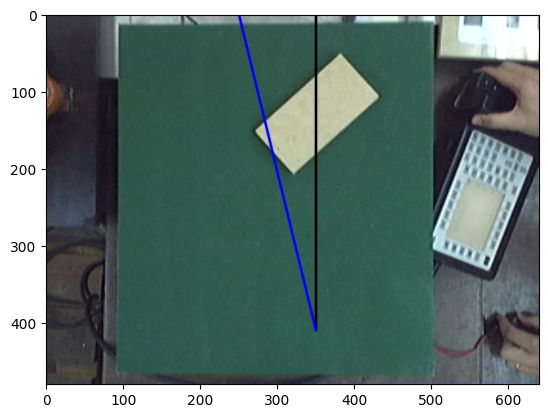

In [26]:
# Leemos la imágen
img = cv.imread('img/imgBloque1.jpg')

# Definimos el punto de inicio de la primera línea
start = (350, 0)

# Definimos el punto final de la primera línea
end = (350, 410)

# Dibujamos una línea
# line(imagen, inicio, fin, color, ancho_linea, tipo_linea)
cv.line(img, start, end, (0,0,0), 2, cv.LINE_AA)

# Dibujamos una segunda línea roja desde el punto (250, 0) hasta el punto (350, 410)
cv.line(img, (250, 0), (350, 410), (255, 0, 0), 2, cv.LINE_AA)

# Mostramos la imagen utilizando matplotlib
# Cambiamos el orden de los canales de color de BGR a RGB
plt.imshow(img[...,::-1])

**cv.line()**

La función cv.line() de OpenCV se utiliza para dibujar una línea en una imagen. Esta función es muy útil para agregar anotaciones gráficas en las imágenes para visualización o procesamiento posterior.

```
cv.line(img, pt1, pt2, color, thickness=None, lineType=None, shift=None)

```

- **img:** La imagen sobre la cual se va a dibujar la línea. Debe ser una matriz de imagen de OpenCV (normalmente obtenida mediante cv.imread()).

- **pt1:** El punto de inicio de la línea. Es una tupla de coordenadas (x, y).

- **pt2:** El punto final de la línea. Es una tupla de coordenadas (x, y).

- **color:** El color de la línea. Para una imagen en escala de grises, este es un valor de intensidad de píxel (por ejemplo, 128). Para una imagen en color, este es un valor de tupla en el formato (B, G, R) (por ejemplo, (255, 0, 0) para azul).

- ***thickness (opcional):*** *El grosor de la línea. Si no se especifica, se utiliza el valor predeterminado de 1.*

- ***lineType (opcional):*** *El tipo de línea. Los valores posibles son:*
  - **cv.LINE_4:** Una línea de 4 conectividades.
  - **cv.LINE_8:** Una línea de 8 conectividades (predeterminado).
  - **cv.LINE_AA:** Una línea antialiased (suavizada).

- ***shift (opcional):*** *Número de bits fraccionarios en las coordenadas del punto. Este parámetro especifica la precisión subpíxel.*

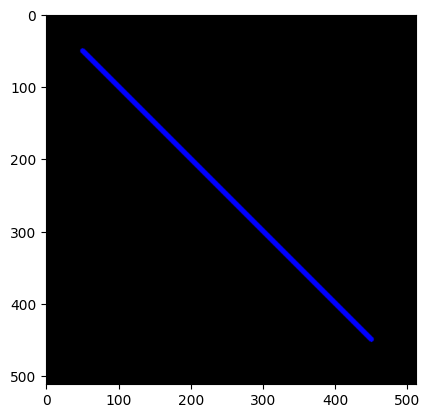

In [27]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Creamos una imagen en blanco (negra en RGB)
img = np.zeros((512, 512, 3), np.uint8) # 512 (filas) x 512 (columnas) x 3 (canales)

# Definimos puntos de inicio y fin
start_point = (50, 50)
end_point = (450, 450)

# Definimos color (B, G, R)
color = (255, 0, 0) # Azul

# Definimos grosor de la línea
thickness = 5

# Dibujar la línea
cv.line(img, start_point, end_point, color, thickness, cv.LINE_AA)

# Mostrar la imagen utilizando matplotlib
plt.imshow(img[..., ::-1])
plt.show()


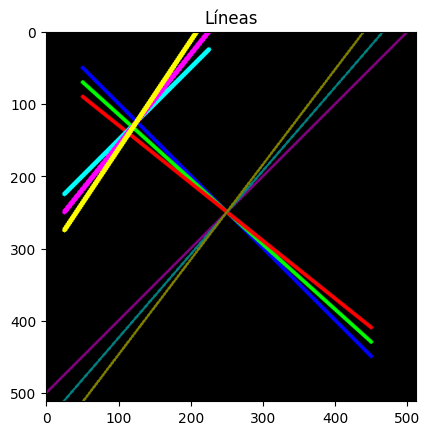

In [28]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Creamos una imagen en blanco (negra)
img = np.zeros((512, 512, 3), np.uint8)

# Definimos colores en formato (B, G, R) openCV
colors = [
    (255, 0, 0),   # Azul
    (0, 255, 0),   # Verde
    (0, 0, 255),   # Rojo
    (255, 255, 0), # Cian
    (255, 0, 255), # Magenta
    (0, 255, 255), # Amarillo
    (128, 0, 128), # Púrpura
    (128, 128, 0), # Oliva
    (0, 128, 128), # Teal
    (255, 128, 0)  # Naranja
]

# Dibujamos 9 líneas con diferentes puntos y diferentes valores de shift
for i in range(3):
    start_point = (50, 50 + i*20)
    end_point = (450, 450 - i*20)
    color = colors[i % len(colors)]
    thickness = 4
    shift = 0
    cv.line(img, start_point, end_point, color, thickness, cv.LINE_AA, shift)

for j in range(3):
    start_point = (50, 450 + j*50)
    end_point = (450, 50 - j*50)
    color = colors[j % len(colors) + 3]
    thickness = 6
    shift = 1
    cv.line(img, start_point, end_point, color, thickness, cv.LINE_4, shift)

for k in range(3):
    start_point = (0, 500 + k*40)
    end_point = (500, 0 - k*40)
    color = colors[k % len(colors) + 6]
    thickness = 2
    shift = 0
    cv.line(img, start_point, end_point, color, thickness, cv.LINE_8, shift)

# Mostrar la imagen utilizando matplotlib
plt.figure()
plt.title(f'Líneas')
plt.imshow(img[..., ::-1])
plt.show()


**Tambien podemos dibujar otras figuras geometricas:**

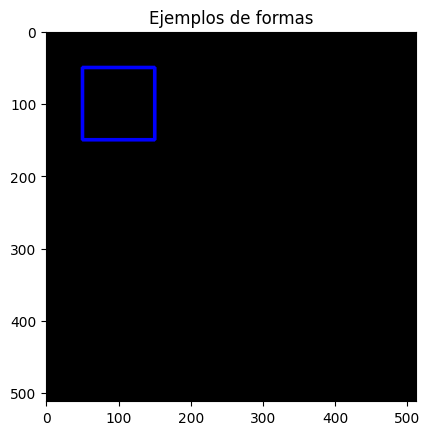

In [29]:
# Creamos una imagen en blanco (negra)
img = np.zeros((512, 512, 3), np.uint8)

# Dibujamos un rectángulo
# cv.rectangle(image, start_point, end_point, color, thickness)
cv.rectangle(img, (50, 50), (150, 150), (255, 0, 0), 3)

# Mostrar la imagen con matplotlib
plt.figure()
plt.imshow(img[..., ::-1])
plt.title('Ejemplos de formas')
plt.show()


La función **cv.rectangle()** de OpenCV se utiliza para dibujar un rectángulo en una imagen.

```
cv.rectangle(img, pt1, pt2, color, thickness=None, lineType=None, shift=None)

```

- **img:** La imagen en la que se va a dibujar el rectángulo.
- **pt1:** Coordenadas de la esquina superior izquierda del rectángulo. Es una tupla (x, y).
- **pt2:** Coordenadas de la esquina inferior derecha del rectángulo. Es una tupla (x, y).
- **color:** Color del rectángulo. Es una tupla (B, G, R), donde B, G y R son los valores de los canales Azul, Verde y Rojo respectivamente.
- **thickness:** Grosor de las líneas del rectángulo. Si se proporciona un valor negativo como -1, se rellenará el rectángulo. El valor predeterminado es 1.
- **lineType:** Tipo de línea. Algunos tipos comunes son cv.LINE_8 (por defecto), cv.LINE_AA (línea antialiased) y cv.LINE_4.
- **shift:** Número de bits de fracción en las coordenadas del punto. Este parámetro es útil para coordenadas sub-píxel.

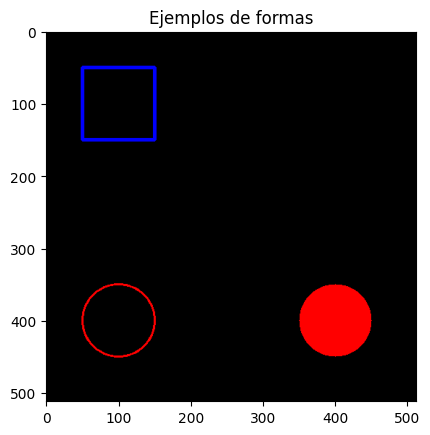

In [30]:
# Dibujamos un círculo
# cv.circle(image, center, radius, color, thickness)
cv.circle(img, (400, 400), 50, (0, 0, 255), -1)
cv.circle(img, (100, 400), 50, (0, 0, 255), 2)

# Mostrar la imagen con matplotlib
plt.figure()
plt.imshow(img[..., ::-1])
plt.title('Ejemplos de formas')
plt.show()

La función **cv.circle()** de OpenCV se utiliza para dibujar un círculo en una imagen.

```
cv.circle(img, center, radius, color, thickness=None, lineType=None, shift=None)
```

- **img:** La imagen en la que se va a dibujar el círculo.
- **center:** Coordenadas del centro del círculo. Es una tupla (x, y).
- **radius:** Radio del círculo. Es un número entero.
- **color:** Color del círculo. Es una tupla (B, G, R), donde B, G y R son los valores de los canales Azul, Verde y Rojo respectivamente.
- **thickness:** Grosor del borde del círculo. Si se proporciona un valor negativo como -1, se rellenará el círculo. El valor predeterminado es 1.
- **lineType:** Tipo de línea. Algunos tipos comunes son cv.LINE_8 (por defecto), cv.LINE_AA (línea antialiased) y cv.LINE_4.
- **shift:** Número de bits de fracción en las coordenadas del punto. Este parámetro es útil para coordenadas sub-píxel.

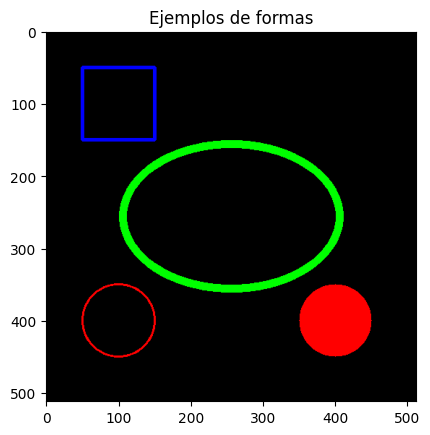

In [31]:
# Dibujamos una elipse
# cv.ellipse(img, center, axes, angle, startAngle, endAngle, color, thickness)
cv.ellipse(img, (256, 256), (150, 100), 0, 0, 360, (0, 255, 0), 10)

# Mostrar la imagen con matplotlib
plt.figure()
plt.imshow(img[..., ::-1])
plt.title('Ejemplos de formas')
plt.show()

La función **cv.ellipse()** de OpenCV se utiliza para dibujar una elipse en una imagen.

- **img:** La imagen en la que se va a dibujar la elipse.
- **center:** Coordenadas del centro de la elipse. Es una tupla (x, y).
- **axes:** Longitud de los ejes mayor y menor de la elipse. Es una tupla (semieje_mayor, semieje_menor).
- **angle:** Ángulo de rotación de la elipse en sentido antihorario.
- **startAngle:** Ángulo inicial del arco que describe la elipse, medido en grados desde el eje x positivo.
- **endAngle:** Ángulo final del arco que describe la elipse, medido en grados desde el eje x positivo.
- **color:** Color de la elipse. Es una tupla (B, G, R), donde B, G y R son los valores de los canales Azul, Verde y Rojo respectivamente.
- **thickness:** Grosor del borde de la elipse. Si se proporciona un valor negativo como -1, se rellenará la elipse. El valor predeterminado es 1.
- **lineType:** Tipo de línea. Algunos tipos comunes son cv.LINE_8 (por defecto), cv.LINE_AA (línea antialiased) y cv.LINE_4.
- **shift:** Número de bits de fracción en las coordenadas del punto. Este parámetro es útil para coordenadas sub-píxel.

[[300 200]
 [400 300]
 [300 400]
 [200 300]]
[[[300 200]]

 [[400 300]]

 [[300 400]]

 [[200 300]]]


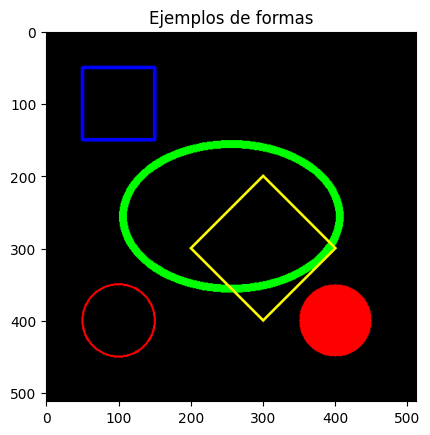

In [32]:
# Dibujamos un polígono
# Definimos puntos del polígono
pts = np.array([[300, 200], [400, 300], [300, 400], [200, 300]], np.int32)
print(pts)
                #(forma, nro_filas, nro_columnas)
pts = pts.reshape((-1, 1, 2)) # Cambios forma del arreglo sin modificar datos (-1=todos_los_elementos, 1=nros_filas, 2=cada_pto_tiene_2_elementos)
print(pts)

# Dibujamos un polígono
# cv.polylines(image, [pts], isClosed, color, thickness)
cv.polylines(img, [pts], isClosed=True, color=(0, 255, 255), thickness=4)

#cv.fillPoly(img, [pts], color=(0, 255, 255))  # Rellenar el polígono con color

# Mostrar la imagen con matplotlib
plt.figure()
plt.imshow(img[..., ::-1])
plt.title('Ejemplos de formas')
plt.show()


La función **cv.polylines()** de OpenCV se utiliza para dibujar polígonos en una imagen.

```
cv.polylines(img, pts, isClosed, color, thickness=None, lineType=None, shift=None)
```
- **img:** La imagen en la que se va a dibujar el polígono.
- **pts:** Una lista de puntos que definen los vértices del polígono. Cada punto es una tupla (x, y).
- **isClosed:** Un booleano que indica si el polígono debe ser cerrado (True) o no (False). Si es True, se unirá el último punto al primer punto.
color: Color del polígono. Es una tupla (B, G, R), donde B, G y R son los valores de los canales Azul, Verde y Rojo respectivamente.
- **thickness:** Grosor del borde del polígono. El valor predeterminado es 1.
- **lineType:** Tipo de línea. Algunos tipos comunes son cv.LINE_8 (por defecto), cv.LINE_AA (línea antialiased) y cv.LINE_4.
- **shift:** Número de bits de fracción en las coordenadas del punto. Este parámetro es útil para coordenadas sub-píxel.

### Texto

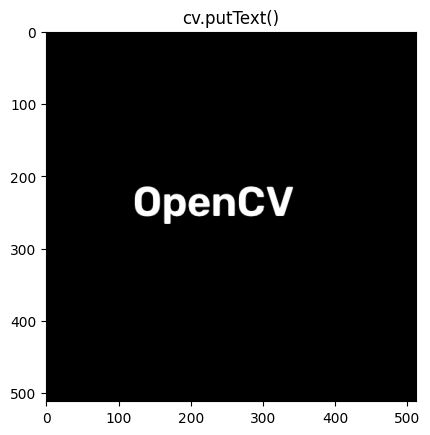

In [33]:
# Dibujamos texto en la imagen
# cv.putText(img, texto, posición, fuente, escala, color, grosor, tipo_línea)
img_texto = np.zeros((512, 512, 3), np.uint8)
cv.putText(img_texto, 'OpenCV', (120, 256), cv.FONT_HERSHEY_SIMPLEX, 2, (255, 255, 255), 3, cv.LINE_AA)

plt.figure()
plt.imshow(img_texto[..., ::-1])
plt.title('cv.putText()')
plt.show()

La función **cv.putText()** de OpenCV se utiliza para escribir texto sobre una imagen.

```
cv.putText(img, text, org, fontFace, fontScale, color, thickness=None, lineType=None)
```

- **img:** la imagen sobre la que se escribe.
- **text:** el texto a dibujar.
- **org:** posición (x, y) de la esquina inferior izquierda del texto.
- **fontFace:** tipografía a usar, por ejemplo `cv.FONT_HERSHEY_SIMPLEX`, `cv.FONT_HERSHEY_COMPLEX`, `cv.FONT_HERSHEY_SCRIPT_SIMPLEX`, entre otras.
- **fontScale:** escala del tamaño de fuente.
- **color, thickness, lineType:** igual que en el resto de las funciones de dibujo.

### Repaso: argumentos comunes a las funciones de dibujo

- **color** se especifica en formato **BGR** (no RGB): por ejemplo `(0, 0, 255)` es rojo, `(0, 255, 0)` es verde y `(255, 0, 0)` es azul.
- **thickness**: grosor del borde en píxeles. Con `-1` se rellena la figura en vez de solo dibujar el borde.
- **lineType**: `cv.LINE_AA` da un trazo suavizado (anti-aliasing); sin especificarlo, OpenCV usa por defecto un trazo "escalonado".
- El origen `(0, 0)` está en la esquina **superior izquierda**: el eje X crece hacia la derecha y el eje Y hacia abajo.

### Ejercicio 1

Realizar el siguiente dibujo utilizando las herramientas de OpenCV.

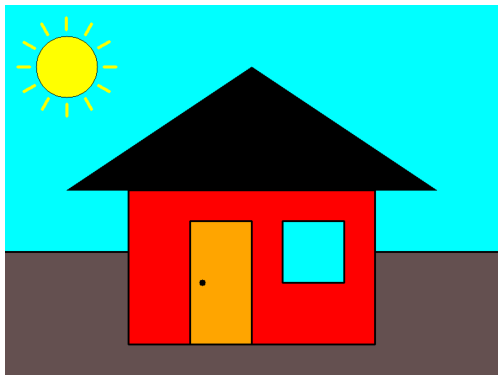

### Resolución 1

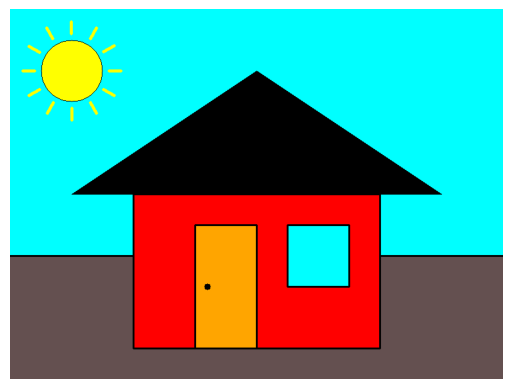

In [34]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Creamos una imagen en blanco
height = 600
width = 800
image = np.zeros((height, width, 3), dtype=np.uint8)

# Definimos colores
white = (255, 255, 255)
black = (0, 0, 0)
yellow = (0, 255, 255)
blue = (255, 0, 0)
cyan = (255, 255, 0)
brown = (80, 80, 100)
red = (0, 0, 255)
orange = (0, 165, 255)

# Dibujamos Cielo
cv.rectangle(image, (0, 0), (width, 400), cyan, -1)

# Dibujamos Tierra
cv.rectangle(image, (0, 400), (width, height), brown, -1)

# Dibujamos línea de horizonte
cv.line(image, (0, 400), (width, 400), black, 2)

# Dibujamos casa
cv.rectangle(image, (200, 300), (600, 550), red, -1)  # Casa
cv.rectangle(image, (200, 300), (600, 550), black, 2)  # marco

pts = np.array([[100, 300], [400, 100], [700, 300]], np.int32)
pts = pts.reshape((-1, 1, 2))
cv.fillPoly(image, [pts], black)  # Techo triangular

cv.rectangle(image, (300, 350), (400, 550), orange, -1)  # Puerta
cv.rectangle(image, (300, 350), (400, 550), black, 2)  # Marco
cv.circle(image, (320, 450), 5, black, -1)  # Manija de la puerta

cv.rectangle(image, (450, 350), (550, 450), cyan, -1)  # Ventana
cv.rectangle(image, (450, 350), (550, 450), black, 2)  # Marco

# Dibujamos sol
cv.circle(image, (100, 100), 50, yellow, -1)  # Sol
cv.circle(image, (100, 100), 50, black, 1)  # Marco

# Dibujamos rayos
for i in range(12):
    x1 = int(100 + 60 * np.cos(i * np.pi / 6))
    y1 = int(100 + 60 * np.sin(i * np.pi / 6))
    x2 = int(100 + 80 * np.cos(i * np.pi / 6))
    y2 = int(100 + 80 * np.sin(i * np.pi / 6))
    cv.line(image, (x1, y1), (x2, y2), yellow, 4)

# Convertir la imagen a RGB (Matplotlib usa RGB)
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Mostrar la imagen con Matplotlib
plt.imshow(image_rgb)
plt.axis('off')  # Ocultar los ejes
plt.show()


### Ejercicio 2

Realizar el siguiente dibujo utilizando las herramientas de OpenCV.

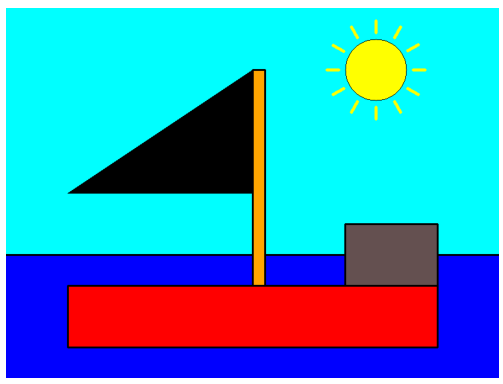

### Resolución 2

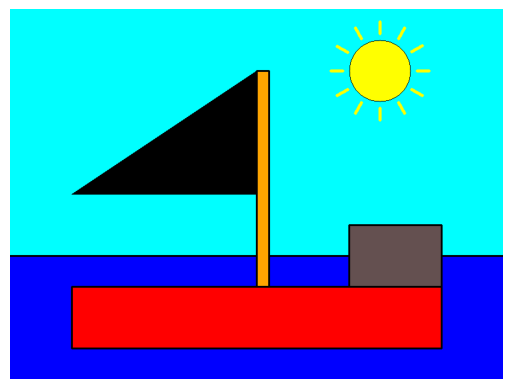

In [35]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Creamos una imagen en blanco
height = 600
width = 800
image = np.zeros((height, width, 3), dtype=np.uint8)

# Definimos colores
white = (255, 255, 255)
black = (0, 0, 0)
yellow = (0, 255, 255)
blue = (255, 0, 0)
cyan = (255, 255, 0)
brown = (80, 80, 100)
red = (0, 0, 255)
orange = (0, 165, 255)

# Dibujamos Cielo
cv.rectangle(image, (0, 0), (width, 400), cyan, -1)

# Dibujamos Mar
cv.rectangle(image, (0, 400), (width, height), blue, -1)

# Dibujamos línea de horizonte
cv.line(image, (0, 400), (width, 400), black, 2)

# Dibujamos barco
cv.rectangle(image, (100, 450), (700, 550), red, -1)  # Barco
cv.rectangle(image, (100, 450), (700, 550), black, 2)  # marco

pts = np.array([[100, 300], [400, 100], [400, 300]], np.int32)
pts = pts.reshape((-1, 1, 2))
cv.fillPoly(image, [pts], black)  # Vela1

cv.rectangle(image, (400, 100), (420, 450), orange, -1)  # Mastil
cv.rectangle(image, (400, 100), (420, 450), black, 2)  # Marco

cv.rectangle(image, (550, 350), (700, 450), brown, -1)  # Cabina
cv.rectangle(image, (550, 350), (700, 450), black, 2)  # Marco

# Dibujamos sol
cv.circle(image, (600, 100), 50, yellow, -1)  # Sol
cv.circle(image, (600, 100), 50, black, 1)  # Marco

# Dibujamos rayos
for i in range(12):
    x1 = int(600 + 60 * np.cos(i * np.pi / 6))
    y1 = int(100 + 60 * np.sin(i * np.pi / 6))
    x2 = int(600 + 80 * np.cos(i * np.pi / 6))
    y2 = int(100 + 80 * np.sin(i * np.pi / 6))
    cv.line(image, (x1, y1), (x2, y2), yellow, 4)

# Convertir la imagen a RGB (Matplotlib usa RGB)
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Mostrar la imagen con Matplotlib
plt.imshow(image_rgb)
plt.axis('off')  # Ocultar los ejes
plt.show()
